# Short-Term Stock Price Prediction Using Machine Learning

Final-year project by Moneeb Hsum, Birmingham City University. This portfolio copy retains the original experiment and saved outputs. See the repository README for dataset setup and evaluation limitations.


In [ ]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from pathlib import Path

from xgboost import XGBRegressor

DATA_PATH = Path(os.environ.get("STOCK_DATA_PATH", "data/all_stocks_5yr.csv"))
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {DATA_PATH}. See the README for the dataset download."
    )
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("Tickers:", df["Name"].nunique())
df.head()


Shape: (619040, 7)
Tickers: 505


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


In [ ]:
# Convert date
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Convert numeric columns
num_cols = ["open", "high", "low", "close", "volume"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Drop missing essential fields + duplicates
df = df.dropna(subset=["date", "open", "high", "low", "close", "volume", "Name"])
df = df.drop_duplicates()

print("After cleaning:", df.shape)
df.isnull().sum()


After cleaning: (619029, 7)


,0
date,0
open,0
high,0
low,0
close,0
volume,0
Name,0


In [ ]:
TICKERS = ["AAPL", "JPM", "XOM"]

df3 = df[df["Name"].isin(TICKERS)].copy()
df3 = df3.sort_values(["Name", "date"]).reset_index(drop=True)

df3.groupby("Name")["date"].agg(["min", "max", "count"])


,min,max,count
Name,,,
AAPL,2013-02-08,2018-02-07,1259
JPM,2013-02-08,2018-02-07,1259
XOM,2013-02-08,2018-02-07,1259


In [ ]:
# Duplicate dates per ticker
dup_dates = df3.duplicated(subset=["Name", "date"]).sum()
print("Duplicate (Name,date) rows:", dup_dates)

# Non-positive price or negative volume checks
bad_rows = df3[
    (df3["open"] <= 0) | (df3["high"] <= 0) | (df3["low"] <= 0) | (df3["close"] <= 0) |
    (df3["volume"] < 0)
]
print("Bad rows:", len(bad_rows))


Duplicate (Name,date) rows: 0
Bad rows: 0


In [ ]:
# Remove rows where low > high (impossible)
df3 = df3[df3["low"] <= df3["high"]].copy()

# Remove rows where open/close outside [low, high] (usually a data quality issue)
df3 = df3[
    (df3["open"].between(df3["low"], df3["high"])) &
    (df3["close"].between(df3["low"], df3["high"]))
].copy()

df3 = df3.sort_values(["Name", "date"]).reset_index(drop=True)
print("After OHLC consistency checks:", df3.shape)


After OHLC consistency checks: (3777, 7)


In [ ]:
def add_returns_and_stats(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()

    d["log_close"] = np.log(d["close"])
    d["log_return_1"] = d["log_close"].diff()
    d["return_1"] = d["close"].pct_change()

    for w in [5, 10, 20]:
        d[f"ma_{w}"] = d["close"].rolling(w).mean()
        d[f"std_{w}"] = d["close"].rolling(w).std()
        d[f"volatility_{w}"] = d["return_1"].rolling(w).std()

    return d


In [ ]:
def add_rsi(d: pd.DataFrame, period: int = 14) -> pd.DataFrame:
    d = d.copy()

    delta = d["close"].diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.ewm(alpha=1/period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, adjust=False).mean()

    rs = avg_gain / (avg_loss + 1e-12)
    d["rsi_14"] = 100 - (100 / (1 + rs))
    return d


In [ ]:
def add_macd(d: pd.DataFrame, fast=12, slow=26, signal=9) -> pd.DataFrame:
    d = d.copy()

    ema_fast = d["close"].ewm(span=fast, adjust=False).mean()
    ema_slow = d["close"].ewm(span=slow, adjust=False).mean()

    d["macd"] = ema_fast - ema_slow
    d["macd_signal"] = d["macd"].ewm(span=signal, adjust=False).mean()
    d["macd_hist"] = d["macd"] - d["macd_signal"]
    return d


In [ ]:
def add_bollinger_bands(d: pd.DataFrame, window=20, num_std=2.0) -> pd.DataFrame:
    d = d.copy()

    mid = d["close"].rolling(window).mean()
    sd = d["close"].rolling(window).std()

    d["bb_mid"] = mid
    d["bb_upper"] = mid + num_std * sd
    d["bb_lower"] = mid - num_std * sd

    d["bb_percent_b"] = (d["close"] - d["bb_lower"]) / ((d["bb_upper"] - d["bb_lower"]) + 1e-12)
    return d


In [ ]:
def add_atr(d: pd.DataFrame, period=14) -> pd.DataFrame:
    d = d.copy()

    prev_close = d["close"].shift(1)

    tr1 = d["high"] - d["low"]
    tr2 = (d["high"] - prev_close).abs()
    tr3 = (d["low"] - prev_close).abs()

    true_range = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    d["atr_14"] = true_range.ewm(alpha=1/period, adjust=False).mean()
    return d


In [ ]:
def add_lags(d: pd.DataFrame, lags=(1, 2, 3, 5)) -> pd.DataFrame:
    d = d.copy()
    for lag in lags:
        d[f"close_lag_{lag}"] = d["close"].shift(lag)
        d[f"return_lag_{lag}"] = d["return_1"].shift(lag)
        d[f"volume_lag_{lag}"] = d["volume"].shift(lag)
    return d


In [ ]:
def build_features_one_ticker(d: pd.DataFrame) -> pd.DataFrame:
    d = d.sort_values("date").copy()

    d = add_returns_and_stats(d)
    d = add_rsi(d)
    d = add_macd(d)
    d = add_bollinger_bands(d)
    d = add_atr(d)
    d = add_lags(d)

    # Regression target: next day close
    d["target_next_close"] = d["close"].shift(-1)

    # Direction label for DA metric
    d["true_direction"] = (d["target_next_close"] > d["close"]).astype(int)

    # Drop rows that become NaN due to rolling windows / lagging / shifting target
    d = d.dropna().reset_index(drop=True)
    return d

engineered_list = []
for t in TICKERS:
    engineered_list.append(build_features_one_ticker(df3[df3["Name"] == t]))

data = pd.concat(engineered_list).reset_index(drop=True)

print("Engineered shape:", data.shape)
data.head()


Engineered shape: (3714, 42)


,date,open,high,low,close,volume,Name,log_close,log_return_1,return_1,...,return_lag_2,volume_lag_2,close_lag_3,return_lag_3,volume_lag_3,close_lag_5,return_lag_5,volume_lag_5,target_next_close,true_direction
0,2013-03-11,61.3928,62.7157,60.7342,62.5528,118272126,AAPL,4.136011,0.014145,0.014246,...,0.011559,116992841.0,60.8088,-0.012714,114903180.0,60.0071,-0.024207,145406366.0,61.2042,0
1,2013-03-12,62.2285,62.6971,61.0814,61.2042,116268341,AAPL,4.114216,-0.021795,-0.021559,...,0.002642,97854442.0,61.5117,0.011559,116992841.0,61.5919,0.026410,159298020.0,61.1928,0
2,2013-03-13,61.2071,62.0714,60.7657,61.1928,101369051,AAPL,4.114030,-0.000186,-0.000186,...,0.014246,118272126.0,61.6742,0.002642,97854442.0,60.8088,-0.012714,114903180.0,61.7857,1
3,2013-03-14,61.8328,62.0914,61.4928,61.7857,75834906,AAPL,4.123672,0.009642,0.009689,...,-0.021559,116268341.0,62.5528,0.014246,118272126.0,61.5117,0.011559,116992841.0,63.3799,1
4,2013-03-15,62.5614,63.4614,62.4642,63.3799,160710606,AAPL,4.149147,0.025475,0.025802,...,-0.000186,101369051.0,61.2042,-0.021559,116268341.0,61.6742,0.002642,97854442.0,65.1028,1


In [ ]:
RAW_FEATURES = ["open", "high", "low", "close", "volume"]

STAT_FEATURES = [
    "return_1", "log_return_1",
    "ma_5", "ma_10", "ma_20",
    "std_5", "std_10", "std_20",
    "volatility_5", "volatility_10", "volatility_20",
]

TECH_FEATURES = [
    "rsi_14",
    "macd", "macd_signal", "macd_hist",
    "bb_mid", "bb_upper", "bb_lower", "bb_percent_b",
    "atr_14",
]

LAG_FEATURES = [c for c in data.columns if c.startswith(("close_lag_", "return_lag_", "volume_lag_"))]

FEATURE_SETS = {
    "Raw": RAW_FEATURES,
    "Stats": RAW_FEATURES + STAT_FEATURES,
    "Technical": RAW_FEATURES + TECH_FEATURES,
    "Hybrid": RAW_FEATURES + STAT_FEATURES + TECH_FEATURES + LAG_FEATURES,
}


In [ ]:
def time_split(d: pd.DataFrame, train_frac=0.8):
    train_parts, test_parts = [], []
    for name, g in d.groupby("Name"):
        g = g.sort_values("date")
        cut = int(len(g) * train_frac)
        train_parts.append(g.iloc[:cut])
        test_parts.append(g.iloc[cut:])
    return pd.concat(train_parts), pd.concat(test_parts)

train_df, test_df = time_split(data, train_frac=0.8)
print("Train:", train_df.shape, "Test:", test_df.shape)


Train: (2970, 42) Test: (744, 42)


In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / (y_true + 1e-12))) * 100

def directional_accuracy(today_close, y_true_next, y_pred_next):
    true_dir = (y_true_next > today_close).astype(int)
    pred_dir = (y_pred_next > today_close).astype(int)
    return (true_dir == pred_dir).mean() * 100


In [ ]:
def train_and_evaluate(feature_cols):
    X_train = train_df[feature_cols]
    y_train = train_df["target_next_close"]

    X_test = test_df[feature_cols]
    y_test = test_df["target_next_close"]
    close_today = test_df["close"].values

    results = []

    # SVR needs scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    svr = SVR(kernel="rbf", C=10, gamma="scale", epsilon=0.1)
    svr.fit(X_train_scaled, y_train)
    pred = svr.predict(X_test_scaled)

    results.append({
        "Model": "SVR",
        "RMSE": rmse(y_test, pred),
        "MAPE%": mape(y_test, pred),
        "R2": r2_score(y_test, pred),
        "DA%": directional_accuracy(close_today, y_test.values, pred)
    })

    # Random Forest (no scaling needed)
    rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    pred = rf.predict(X_test)

    results.append({
        "Model": "Random Forest",
        "RMSE": rmse(y_test, pred),
        "MAPE%": mape(y_test, pred),
        "R2": r2_score(y_test, pred),
        "DA%": directional_accuracy(close_today, y_test.values, pred)
    })

    xgb = XGBRegressor(
        n_estimators=800,
        learning_rate=0.03,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42
    )
    xgb.fit(X_train, y_train)
    pred = xgb.predict(X_test)

    results.append({
        "Model": "XGBoost",
        "RMSE": rmse(y_test, pred),
        "MAPE%": mape(y_test, pred),
        "R2": r2_score(y_test, pred),
        "DA%": directional_accuracy(close_today, y_test.values, pred)
    })

    return pd.DataFrame(results).sort_values("RMSE")


In [ ]:
all_results = []
for fs_name, cols in FEATURE_SETS.items():
    res = train_and_evaluate(cols)
    res.insert(0, "FeatureSet", fs_name)
    all_results.append(res)

results_table = pd.concat(all_results).reset_index(drop=True)
results_table


,FeatureSet,Model,RMSE,MAPE%,R2,DA%
0,Raw,XGBoost,15.600262,5.475449,0.782351,51.344086
1,Raw,Random Forest,16.747486,5.998558,0.749163,46.370968
2,Raw,SVR,31.804030,10.410776,0.095401,50.537634
3,Stats,XGBoost,16.720261,5.981162,0.749978,51.075269
4,Stats,Random Forest,16.899056,6.046129,0.744602,48.655914
5,Stats,SVR,29.542382,9.932355,0.219482,49.327957
6,Technical,XGBoost,16.944987,6.082462,0.743212,50.268817
7,Technical,Random Forest,17.063556,6.121558,0.739606,47.580645
8,Technical,SVR,28.917234,9.843280,0.252166,50.806452
9,Hybrid,Random Forest,16.658626,5.941979,0.751818,47.849462


In [ ]:
df.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


In [ ]:
data.head()

,date,open,high,low,close,volume,Name,log_close,log_return_1,return_1,...,return_lag_2,volume_lag_2,close_lag_3,return_lag_3,volume_lag_3,close_lag_5,return_lag_5,volume_lag_5,target_next_close,true_direction
0,2013-03-11,61.3928,62.7157,60.7342,62.5528,118272126,AAPL,4.136011,0.014145,0.014246,...,0.011559,116992841.0,60.8088,-0.012714,114903180.0,60.0071,-0.024207,145406366.0,61.2042,0
1,2013-03-12,62.2285,62.6971,61.0814,61.2042,116268341,AAPL,4.114216,-0.021795,-0.021559,...,0.002642,97854442.0,61.5117,0.011559,116992841.0,61.5919,0.026410,159298020.0,61.1928,0
2,2013-03-13,61.2071,62.0714,60.7657,61.1928,101369051,AAPL,4.114030,-0.000186,-0.000186,...,0.014246,118272126.0,61.6742,0.002642,97854442.0,60.8088,-0.012714,114903180.0,61.7857,1
3,2013-03-14,61.8328,62.0914,61.4928,61.7857,75834906,AAPL,4.123672,0.009642,0.009689,...,-0.021559,116268341.0,62.5528,0.014246,118272126.0,61.5117,0.011559,116992841.0,63.3799,1
4,2013-03-15,62.5614,63.4614,62.4642,63.3799,160710606,AAPL,4.149147,0.025475,0.025802,...,-0.000186,101369051.0,61.2042,-0.021559,116268341.0,61.6742,0.002642,97854442.0,65.1028,1


In [ ]:
data[["close","rsi_14","macd","bb_upper","atr_14","close_lag_1"]].head()

,close,rsi_14,macd,bb_upper,atr_14,close_lag_1
0,62.5528,52.551172,-1.501781,68.445510,1.527608,61.6742
1,61.2042,46.610690,-1.495274,67.635127,1.533900,62.5528
2,61.1928,46.562774,-1.474045,67.142538,1.517600,61.2042
3,61.7857,49.472094,-1.393318,66.564748,1.473386,61.1928
4,63.3799,56.353034,-1.187019,65.961118,1.487837,61.7857


In [ ]:
dup_dates = df3.duplicated(subset=["Name","date"]).sum()
print(dup_dates)

0


In [ ]:
df.isnull().sum()
df.duplicated().sum()

np.int64(0)

In [ ]:
df3.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


In [ ]:
data[["close","rsi_14","macd","bb_upper","atr_14","close_lag_1"]].head()

,close,rsi_14,macd,bb_upper,atr_14,close_lag_1
0,62.5528,52.551172,-1.501781,68.445510,1.527608,61.6742
1,61.2042,46.610690,-1.495274,67.635127,1.533900,62.5528
2,61.1928,46.562774,-1.474045,67.142538,1.517600,61.2042
3,61.7857,49.472094,-1.393318,66.564748,1.473386,61.1928
4,63.3799,56.353034,-1.187019,65.961118,1.487837,61.7857


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

FIG_DIR = Path("fyp_figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

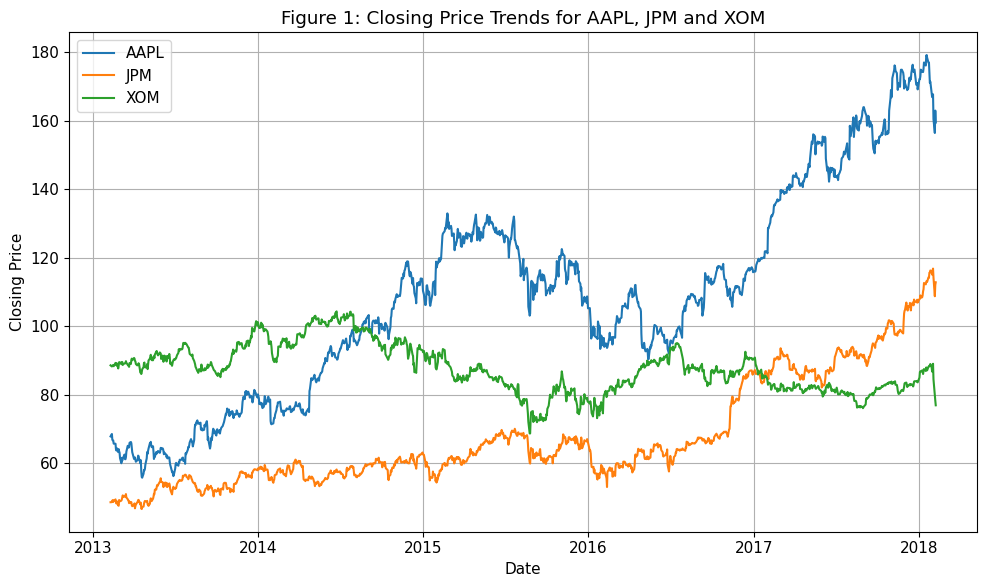

In [ ]:
plt.figure()

for ticker in TICKERS:
    temp = df3[df3["Name"] == ticker].sort_values("date")
    plt.plot(temp["date"], temp["close"], label=ticker)

plt.title("Figure 1: Closing Price Trends for AAPL, JPM and XOM")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "figure_1_stock_price_trends.png", dpi=300)
plt.show()

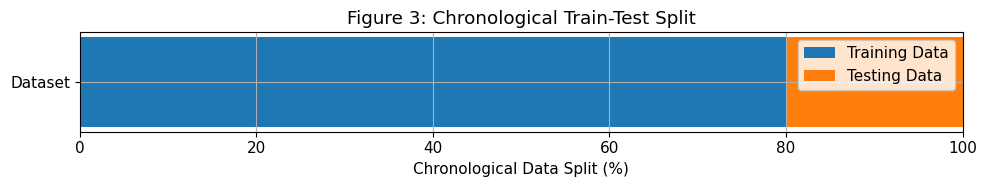

In [ ]:
plt.figure(figsize=(10, 2))

plt.barh(["Dataset"], [80], left=[0], label="Training Data")
plt.barh(["Dataset"], [20], left=[80], label="Testing Data")

plt.xlim(0, 100)
plt.xlabel("Chronological Data Split (%)")
plt.title("Figure 3: Chronological Train-Test Split")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "figure_3_train_test_split.png", dpi=300)
plt.show()

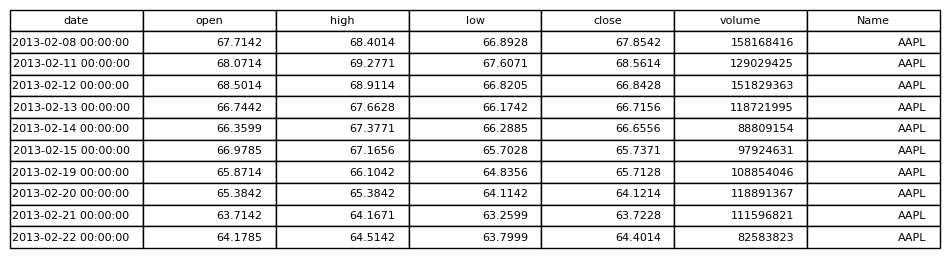

In [ ]:
preview = df3.head(10)

fig, ax = plt.subplots(figsize=(12, 3))
ax.axis("off")

table = ax.table(
    cellText=preview[["date", "open", "high", "low", "close", "volume", "Name"]].values,
    colLabels=["date", "open", "high", "low", "close", "volume", "Name"],
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

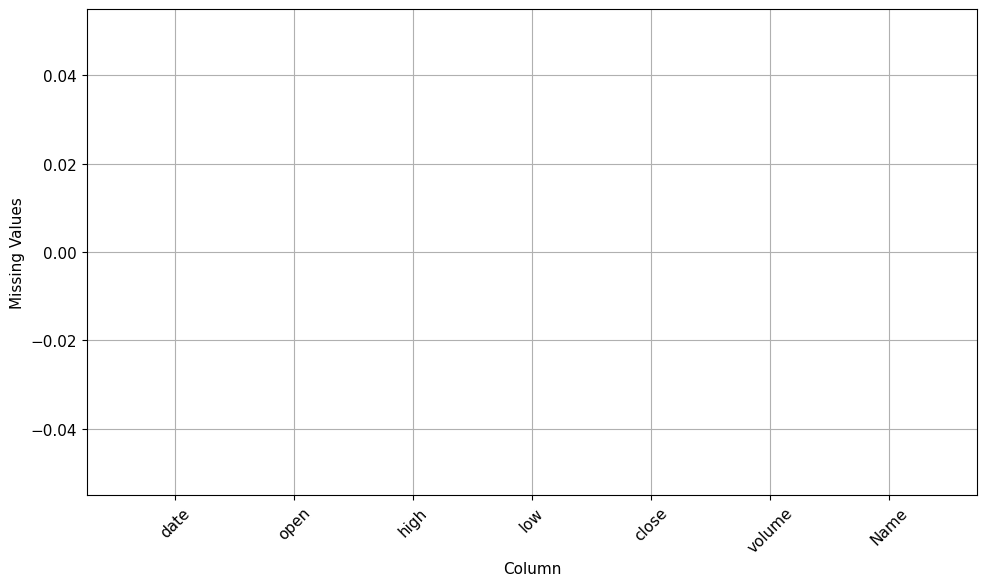

In [ ]:
missing_counts = df3.isnull().sum()

plt.figure()
plt.bar(missing_counts.index, missing_counts.values)
plt.xlabel("Column")
plt.ylabel("Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()

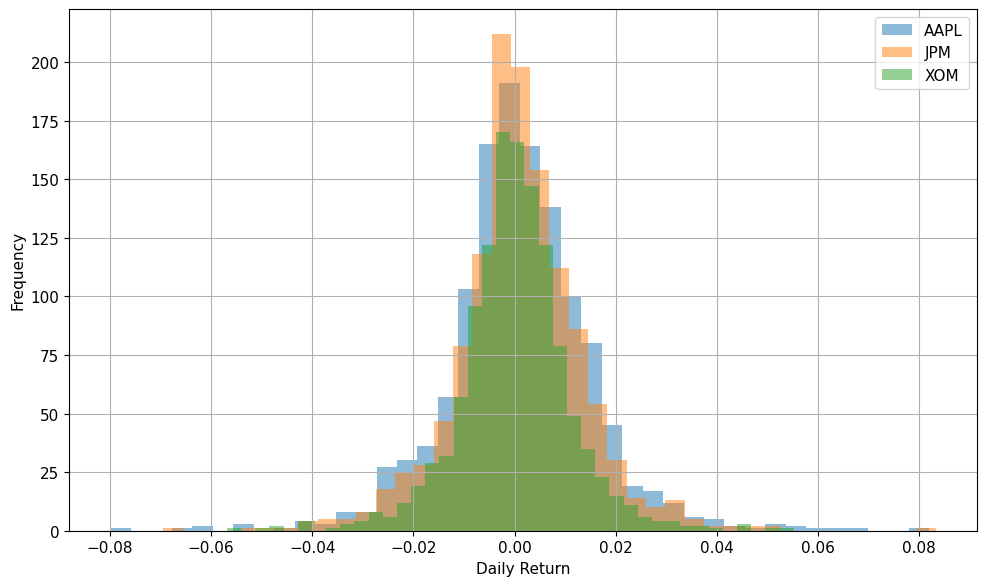

In [ ]:
plt.figure()

for ticker in TICKERS:
    temp = data[data["Name"] == ticker]
    plt.hist(temp["return_1"], bins=40, alpha=0.5, label=ticker)

plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

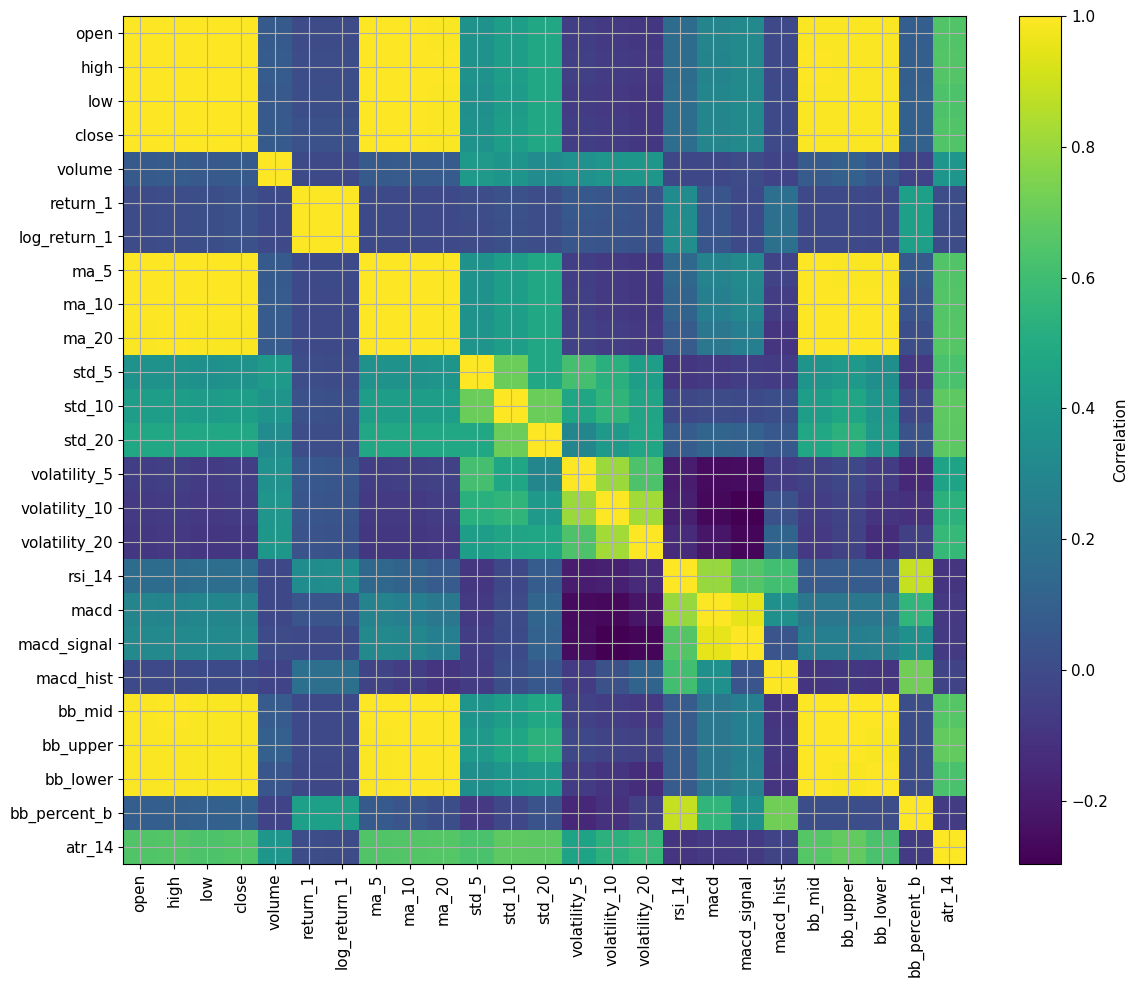

In [ ]:
corr_features = RAW_FEATURES + STAT_FEATURES + TECH_FEATURES
corr_data = data[corr_features].corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr_data, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(range(len(corr_features)), corr_features, rotation=90)
plt.yticks(range(len(corr_features)), corr_features)
plt.tight_layout()


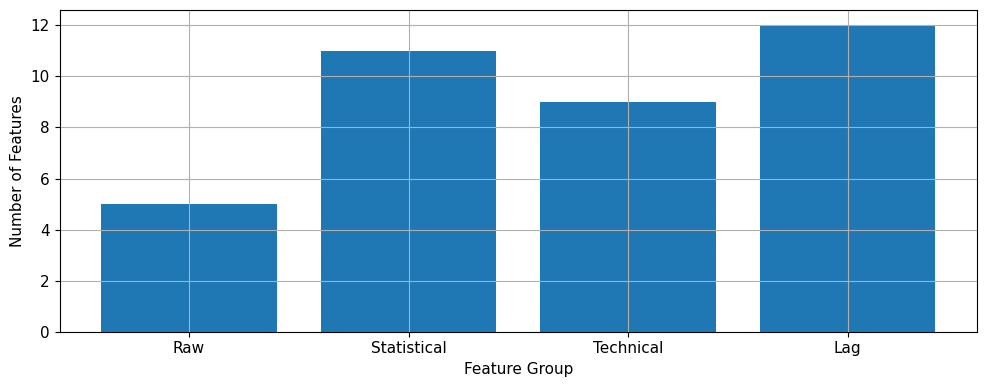

In [ ]:
plt.figure(figsize=(10, 4))

groups = {
    "Raw": len(RAW_FEATURES),
    "Statistical": len(STAT_FEATURES),
    "Technical": len(TECH_FEATURES),
    "Lag": len(LAG_FEATURES)
}

plt.bar(groups.keys(), groups.values())
plt.xlabel("Feature Group")
plt.ylabel("Number of Features")
plt.tight_layout()

In [ ]:
results_display = results_table.copy()
results_display["RMSE"] = results_display["RMSE"].round(2)
results_display["MAPE%"] = results_display["MAPE%"].round(2)
results_display["R2"] = results_display["R2"].round(3)
results_display["DA%"] = results_display["DA%"].round(2)

results_display

,FeatureSet,Model,RMSE,MAPE%,R2,DA%
0,Raw,XGBoost,15.60,5.48,0.782,51.34
1,Raw,Random Forest,16.75,6.00,0.749,46.37
2,Raw,SVR,31.80,10.41,0.095,50.54
3,Stats,XGBoost,16.72,5.98,0.750,51.08
4,Stats,Random Forest,16.90,6.05,0.745,48.66
5,Stats,SVR,29.54,9.93,0.219,49.33
6,Technical,XGBoost,16.94,6.08,0.743,50.27
7,Technical,Random Forest,17.06,6.12,0.740,47.58
8,Technical,SVR,28.92,9.84,0.252,50.81
9,Hybrid,Random Forest,16.66,5.94,0.752,47.85


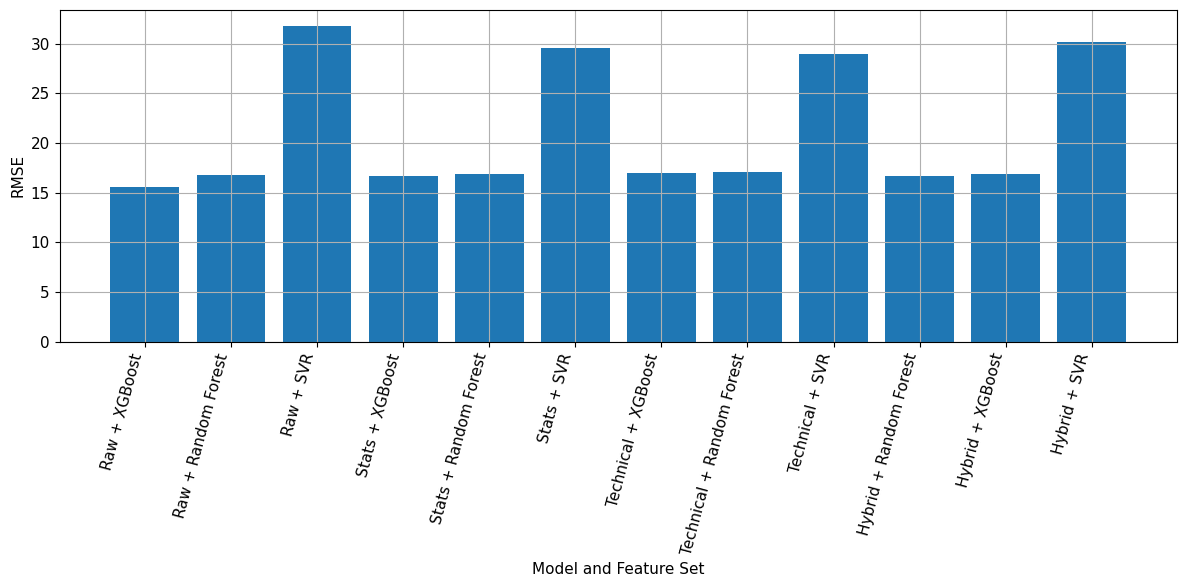

In [ ]:
plot_data = results_table.copy()
plot_data["Label"] = plot_data["FeatureSet"] + " + " + plot_data["Model"]

plt.figure(figsize=(12, 6))
plt.bar(plot_data["Label"], plot_data["RMSE"])
plt.xlabel("Model and Feature Set")
plt.ylabel("RMSE")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()

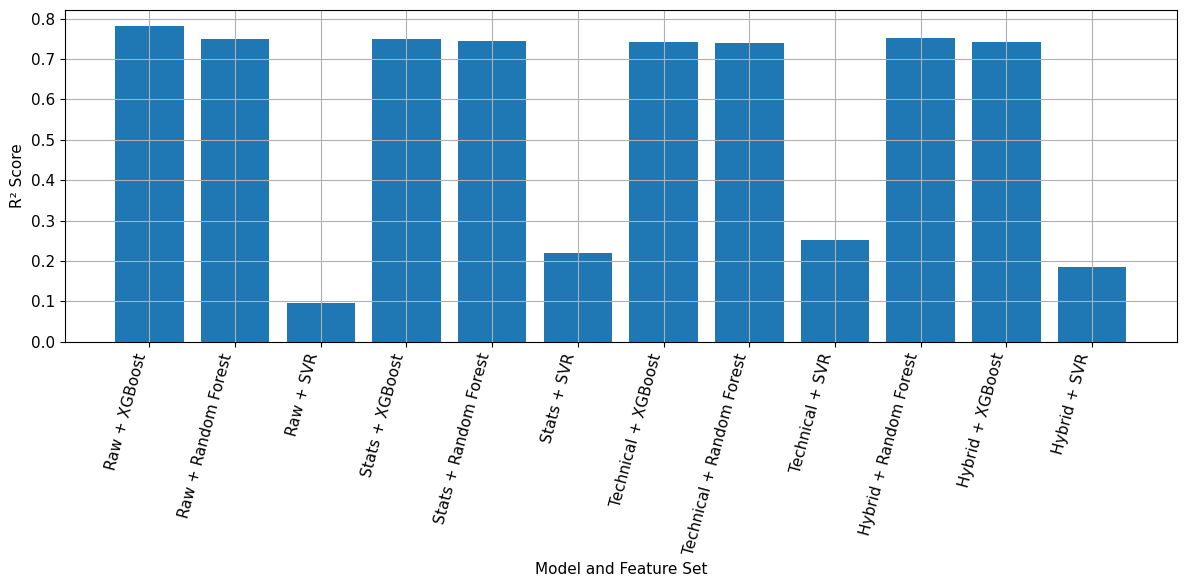

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(plot_data["Label"], plot_data["R2"])
plt.xlabel("Model and Feature Set")
plt.ylabel("R² Score")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()

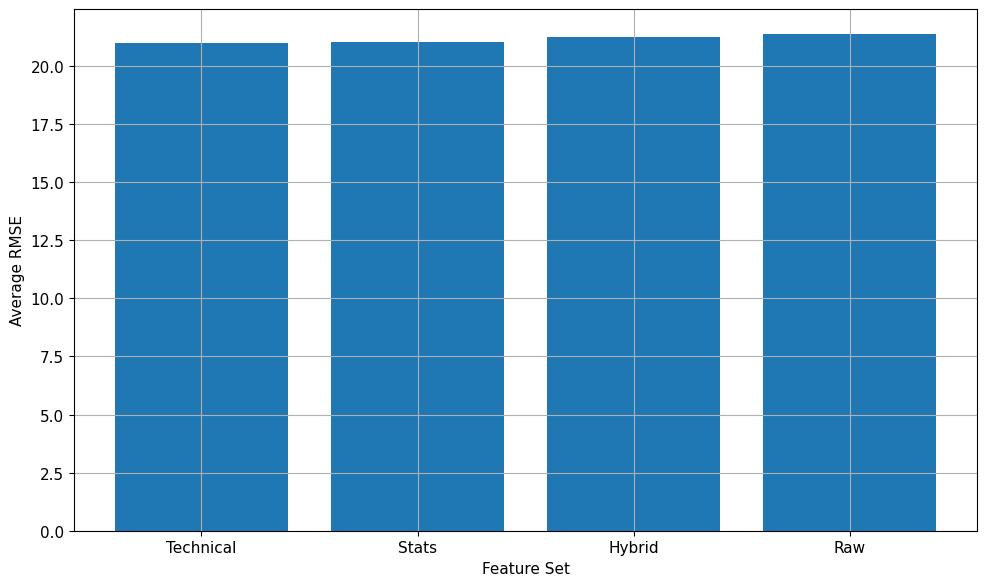

In [ ]:
feature_rmse = results_table.groupby("FeatureSet")["RMSE"].mean().sort_values()

plt.figure()
plt.bar(feature_rmse.index, feature_rmse.values)
plt.xlabel("Feature Set")
plt.ylabel("Average RMSE")
plt.tight_layout()

In [ ]:
def train_best_model_and_get_predictions(feature_cols):
    X_train = train_df[feature_cols]
    y_train = train_df["target_next_close"]

    X_test = test_df[feature_cols]
    y_test = test_df["target_next_close"]

    xgb = XGBRegressor(
        n_estimators=800,
        learning_rate=0.03,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42
    )

    xgb.fit(X_train, y_train)
    predictions = xgb.predict(X_test)

    pred_df = test_df[["date", "Name", "close", "target_next_close"]].copy()
    pred_df["prediction"] = predictions

    return xgb, pred_df

best_model, pred_df = train_best_model_and_get_predictions(FEATURE_SETS["Raw"])

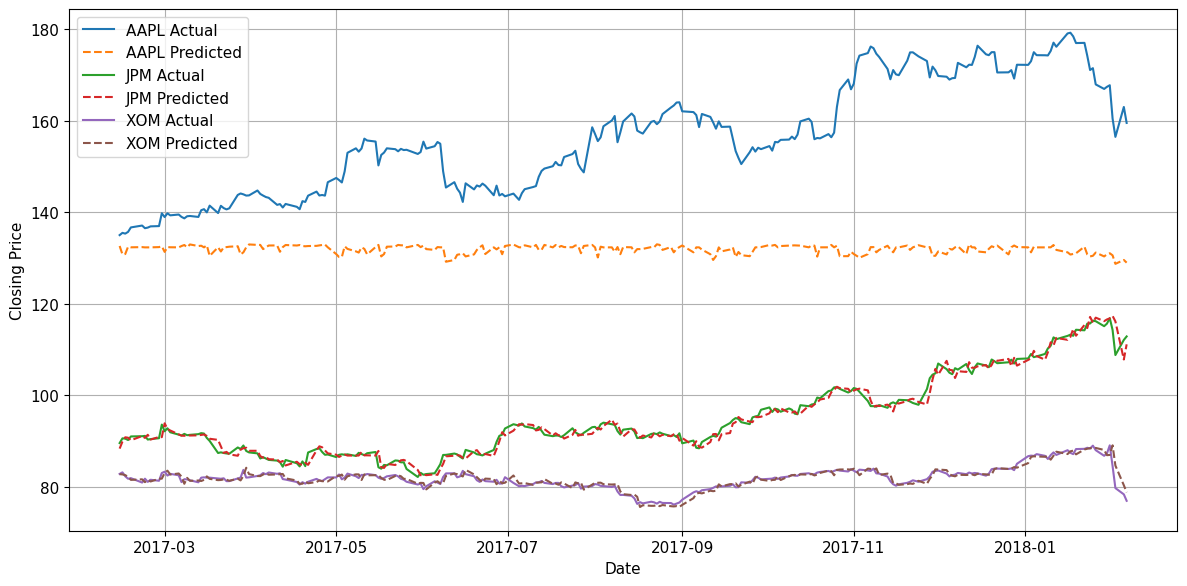

In [ ]:
plt.figure(figsize=(12, 6))

for ticker in TICKERS:
    temp = pred_df[pred_df["Name"] == ticker].sort_values("date")
    plt.plot(temp["date"], temp["target_next_close"], label=f"{ticker} Actual")
    plt.plot(temp["date"], temp["prediction"], linestyle="--", label=f"{ticker} Predicted")

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.tight_layout()

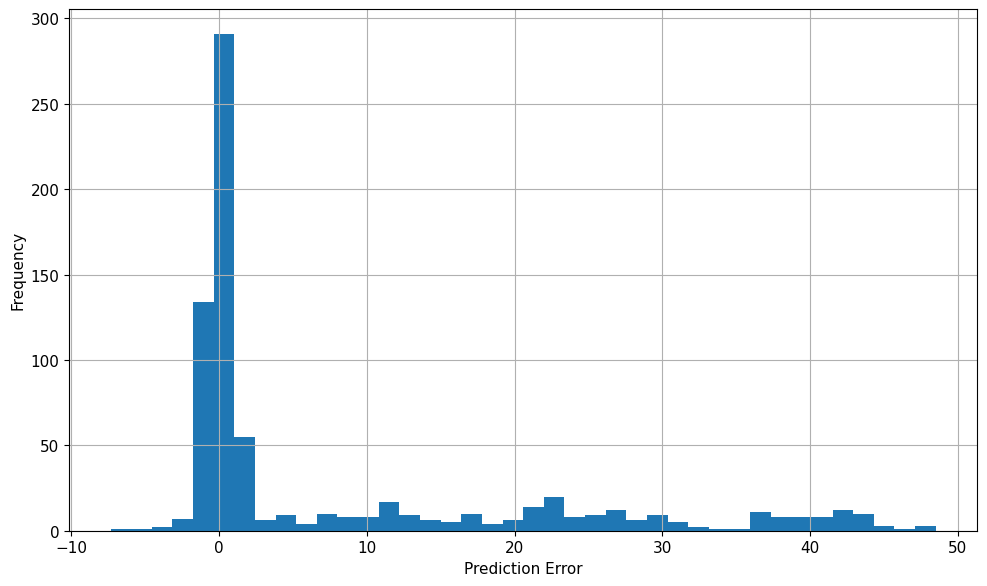

In [ ]:
pred_df["error"] = pred_df["target_next_close"] - pred_df["prediction"]

plt.figure()
plt.hist(pred_df["error"], bins=40)
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.tight_layout()

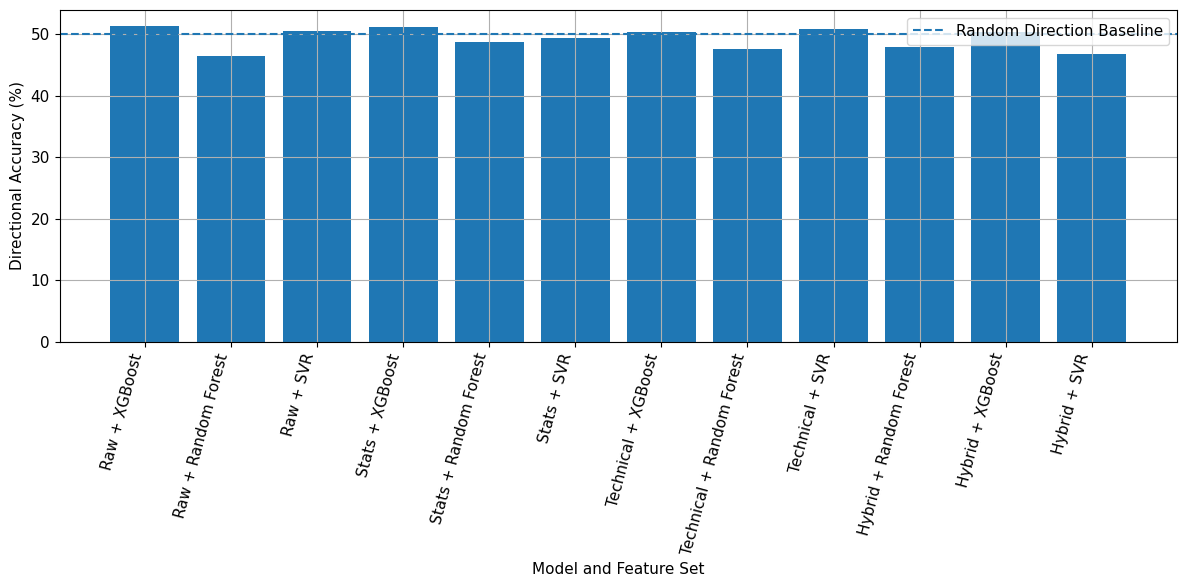

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(plot_data["Label"], plot_data["DA%"])
plt.axhline(50, linestyle="--", label="Random Direction Baseline")
plt.xlabel("Model and Feature Set")
plt.ylabel("Directional Accuracy (%)")
plt.xticks(rotation=75, ha="right")
plt.legend()
plt.tight_layout()

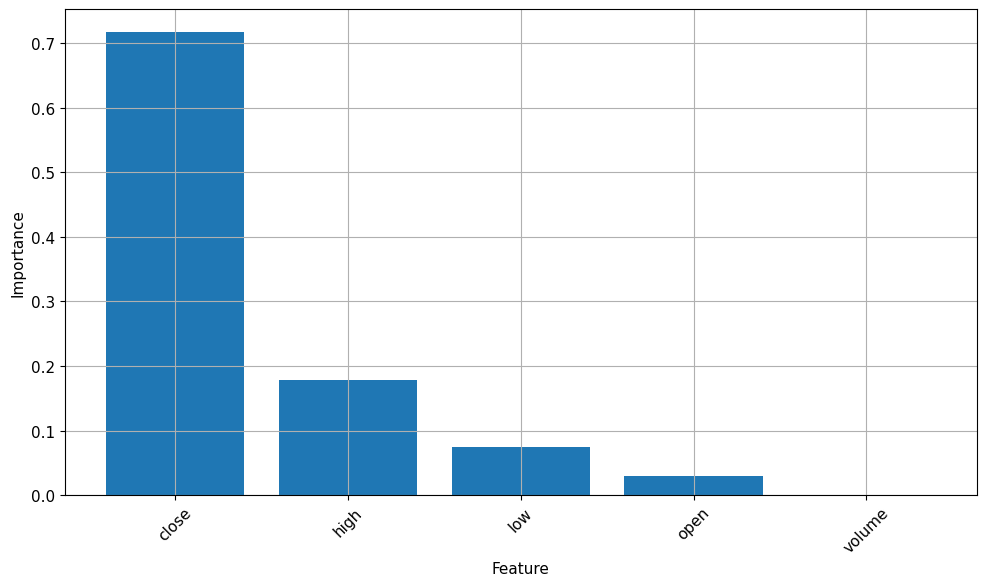

In [ ]:
importance = pd.DataFrame({
    "Feature": FEATURE_SETS["Raw"],
    "Importance": best_model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure()
plt.bar(importance["Feature"], importance["Importance"])
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()